In [1]:
from pathlib import Path
import sys

import torch
import torch.nn as nn
import torchvision.models as models

from torchvision.models import ResNet50_Weights
from torch.utils.data import DataLoader

from datasets import load_from_disk
from tqdm.auto import tqdm

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

PROJECT_ROOT = Path.cwd().parent

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("Project Root:", PROJECT_ROOT)

Device: cuda
Project Root: Y:\Python\AI ML\Month 2\week 8-NLP\46 — LANDMARK RECOGNITION


In [2]:
dataset = load_from_disk(
    PROJECT_ROOT / "datasets/landmark_recognition"
)

test_dataset = dataset["test"]

print("Test samples:", len(test_dataset))
print("Features:", test_dataset.features)

Test samples: 9116
Features: {'id': Value('string'), 'landmark_id': Value('int64'), 'category': Value('string'), 'image': Image(mode=None, decode=True), 'label': Value('int64')}


In [3]:
from torchvision import transforms

test_transform = transforms.Compose([

    transforms.Resize(256),

    transforms.CenterCrop(224),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )

])

In [4]:
BEST_MODEL_PATH = (
    PROJECT_ROOT / "checkpoints" / "best_feature_extraction.pth"
)

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

print("Best model epoch:", checkpoint["epoch"])

print(
    "Best validation accuracy:",
    f'{checkpoint["best_val_accuracy"] * 100:.2f}%'
)

Best model epoch: 15
Best validation accuracy: 88.51%


In [5]:
sys.path.insert(0,str(PROJECT_ROOT))
    
from src.preprocessing import LandmarkDataset

test_torch_dataset = LandmarkDataset(
    hf_dataset=test_dataset,
    category_to_label=checkpoint["category_to_label"],
    transform=test_transform
)

In [6]:
test_loader = DataLoader(
    test_torch_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("Test dataset size:", len(test_torch_dataset))
print("Number of test batches:", len(test_loader))

Test dataset size: 9116
Number of test batches: 285


In [7]:
images, labels = next(iter(test_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("First 10 labels:", labels[:10])

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
First 10 labels: tensor([ 5, 30, 26, 49, 34, 32,  4, 27, 31, 15])


In [8]:
NUM_CLASSES = len(checkpoint["category_to_label"])

model = models.resnet50(weights=None)

model.fc = nn.Linear(
    in_features=2048,
    out_features=NUM_CLASSES
)

model = model.to(device)

print("Number of classes:", NUM_CLASSES)
print("Model loaded on:", device)

Number of classes: 51
Model loaded on: cuda


In [9]:
model.load_state_dict(checkpoint["model_state_dict"])

model.eval()

print("Model is in evaluation mode:", not model.training)

Model is in evaluation mode: True


In [10]:
model.eval()

y_true = []
y_pred = []
y_prob = []

with torch.inference_mode():

    for images, labels in tqdm(test_loader, desc="Testing"):

        images = images.to(device)

        # Forward pass
        outputs = model(images)

        # Convert logits into probabilities
        probabilities = torch.softmax(outputs, dim=1)

        # Get predicted class
        predictions = torch.argmax(outputs, dim=1)

        # Store results
        y_true.extend(labels.numpy())
        y_pred.extend(predictions.cpu().numpy())
        y_prob.extend(probabilities.cpu().numpy())

# Convert lists into NumPy arrays
y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_prob = np.array(y_prob)

print("\nInference completed!")

print("Actual labels shape:", y_true.shape)
print("Predicted labels shape:", y_pred.shape)
print("Probability matrix shape:", y_prob.shape)

Testing:   0%|          | 0/285 [00:00<?, ?it/s]


Inference completed!
Actual labels shape: (9116,)
Predicted labels shape: (9116,)
Probability matrix shape: (9116, 51)


In [11]:
class_names = [
    checkpoint["label_to_category"][i]
    for i in range(NUM_CLASSES)
]

report = classification_report(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    zero_division=0
)

print(report)

                                                        precision    recall  f1-score   support

                                       %C3%87ufut_Qale       0.85      0.88      0.86       104
                                          Akbar's_Tomb       0.89      0.89      0.89       116
                                     Akkerman_fortress       0.78      0.76      0.77       148
               Catedral_San_Sebasti%C3%A1n,_Cochabamba       0.90      0.96      0.93       166
                                     Corktown,_Toronto       0.86      0.79      0.82       447
                                    Douthat_State_Park       0.76      0.83      0.80       117
                                      Edinburgh_Castle       0.82      0.90      0.86       165
                                          Eiffel_Tower       0.97      0.84      0.90       147
                Episcopal_Diocese_of_Southwest_Florida       0.96      0.99      0.98       109
                                       

In [12]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES)
)

import pandas as pd

cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

pd.set_option("display.max_rows", 60)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 300)

display(cm_df)

,%C3%87ufut_Qale,Akbar's_Tomb,Akkerman_fortress,"Catedral_San_Sebasti%C3%A1n,_Cochabamba","Corktown,_Toronto",Douthat_State_Park,Edinburgh_Castle,Eiffel_Tower,Episcopal_Diocese_of_Southwest_Florida,Faisal_Mosque,Feroz_Shah_Kotla,Genoese_fortress_(Sudak),Golden_Gate_Bridge,Grand_Canyon,Grote_of_Onze-Lieve-Vrouwekerk_(Breda),Haghpat,Haleakal%C4%81_National_Park,Harichavank,Hayravank_monastery,Isa_Khan_Niyazi's_tomb,Itmad-Ud-Daulah's_Tomb,Jurassic_Coast,Kecharis,Khotyn_Fortress,Lake_Como,Ljubljana_Castle,Lviv,Madrid_R%C3%ADo,Masada,Mathura_Museum,Matka_Canyon,Media_contributed_by_the_ETH-Bibliothek,Museum_of_Folk_Architecture_and_Ethnography_in_Pyrohiv,Niagara_Falls,Nieuwe_Waterweg,Noraduz_Cemetery,Nyhavn,Ogrodzieniec_Castle,Pakistan_Monument_Islamabad,Pe%C5%A1ter,Perperikon,Purana_Qila,"Qutb_Minar_and_its_monuments,_Delhi",Saint_Holy_Mother_church_of_Yeghvard,Sal%C3%A8ve,Skopje_Fortress,Sofiyivsky_Park,St._Hripsime_church_in_Vagharshapat,"St._Lawrence,_Toronto","Victoria_Memorial,_Kolkata",York_River_State_Park
%C3%87ufut_Qale,91,0,1,0,0,0,1,0,0,0,2,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,2,0,0,0,0,0,0,1,0,0,3,0,0,0,0,0,0,0,0,0,1
Akbar's_Tomb,0,103,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,8,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0
Akkerman_fortress,2,0,113,0,0,0,1,0,0,0,1,8,0,0,0,0,0,0,1,0,0,2,0,2,0,0,0,1,0,0,0,0,1,0,0,1,0,0,0,0,0,1,1,0,0,11,1,0,1,0,0
"Catedral_San_Sebasti%C3%A1n,_Cochabamba",0,0,0,159,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,2,0,0,0,0,0,0,0,0,0,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0
"Corktown,_Toronto",0,0,0,2,352,1,0,0,0,0,0,2,1,0,0,0,0,0,0,0,0,1,0,0,1,2,1,3,0,0,0,0,0,1,9,0,1,0,0,1,0,0,0,0,1,0,0,0,68,0,0
Douthat_State_Park,0,0,0,0,0,97,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,2,0,2,0,0,0,0,0,3,1,0,0,0,0,0,0,1,0,0,0,1,0,3,0,0,0,5
Edinburgh_Castle,0,0,0,0,2,1,149,1,0,0,1,1,0,0,0,1,0,0,0,0,0,1,0,0,1,0,1,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,4,0,0,0,0,0
Eiffel_Tower,0,0,0,0,3,0,4,124,0,0,0,0,2,0,0,0,0,0,0,0,0,0,0,0,1,1,3,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,4,0,4,0,0
Episcopal_Diocese_of_Southwest_Florida,0,0,0,0,0,0,0,0,108,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
Faisal_Mosque,0,0,0,0,0,0,0,0,0,126,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0


In [13]:
# Copy confusion matrix and remove diagonal
cm_errors = cm.copy()
np.fill_diagonal(cm_errors, 0)

# Get all non-zero misclassifications
error_pairs = []

for actual_idx in range(NUM_CLASSES):
    for predicted_idx in range(NUM_CLASSES):

        if cm_errors[actual_idx, predicted_idx] > 0:

            error_pairs.append({
                "Actual Landmark": class_names[actual_idx],
                "Predicted Landmark": class_names[predicted_idx],
                "Misclassified Images": cm_errors[
                    actual_idx, predicted_idx
                ]
            })

# Sort by highest error count
error_df = pd.DataFrame(error_pairs)

error_df = error_df.sort_values(
    by="Misclassified Images",
    ascending=False
)

display(error_df.head(20))

,Actual Landmark,Predicted Landmark,Misclassified Images
49,"Corktown,_Toronto","St._Lawrence,_Toronto",68
443,"St._Lawrence,_Toronto","Corktown,_Toronto",40
285,Media_contributed_by_the_ETH-Bibliothek,Jurassic_Coast,20
291,Media_contributed_by_the_ETH-Bibliothek,Madrid_R%C3%ADo,15
288,Media_contributed_by_the_ETH-Bibliothek,Lake_Como,13
292,Media_contributed_by_the_ETH-Bibliothek,Masada,12
27,Akkerman_fortress,Skopje_Fortress,11
336,Noraduz_Cemetery,Hayravank_monastery,11
271,Media_contributed_by_the_ETH-Bibliothek,Akkerman_fortress,10
306,Media_contributed_by_the_ETH-Bibliothek,Sofiyivsky_Park,9


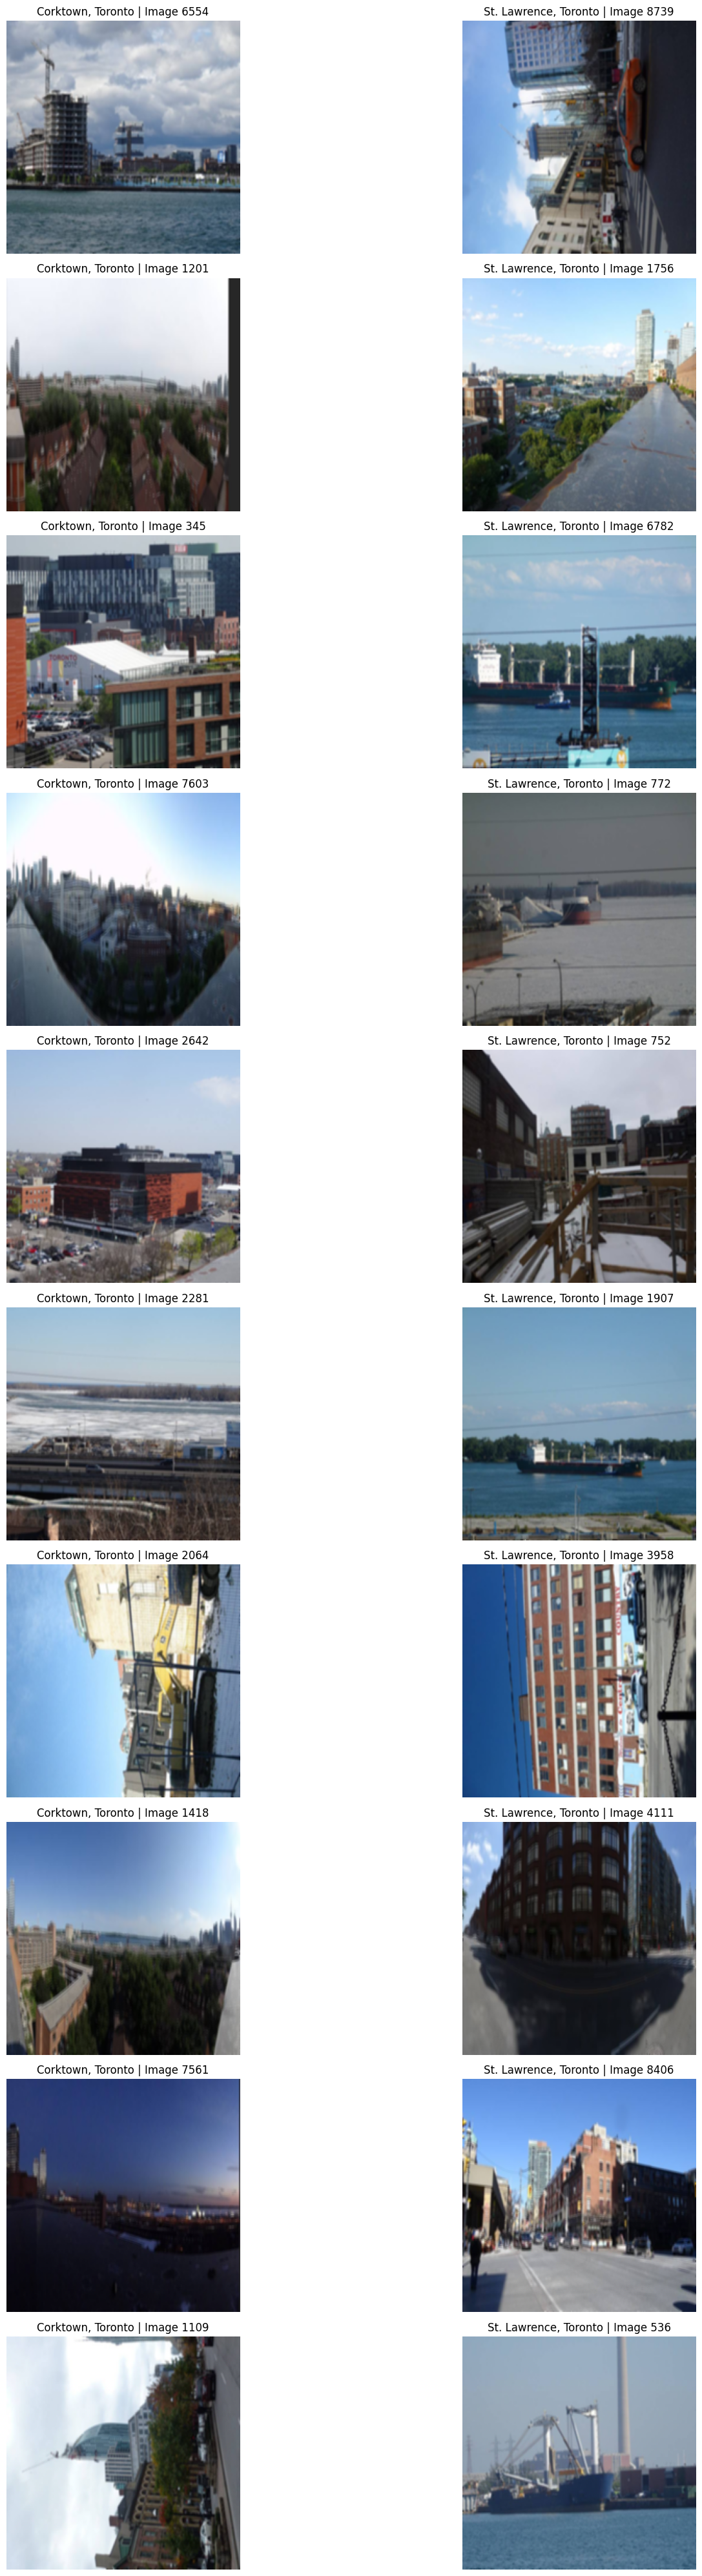

In [14]:
import random
import matplotlib.pyplot as plt

categories_to_compare = [
    "Corktown,_Toronto",
    "St._Lawrence,_Toronto"
]

rng = random.Random(42)

fig, axes = plt.subplots(
    10, 2,
    figsize=(18, 40)
)

for col, category in enumerate(categories_to_compare):

    class_indices = [
        i for i, name in enumerate(test_dataset["category"])
        if name == category
    ]

    selected_indices = rng.sample(class_indices, 10)

    for row, idx in enumerate(selected_indices):

        sample = test_dataset[idx]

        axes[row, col].imshow(sample["image"])
        axes[row, col].set_title(
            f"{category.replace('_', ' ')} | Image {idx}",
            fontsize=12
        )
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

## Misclassification Analysis — Corktown vs St. Lawrence

### Observation

The model showed significant confusion between **Corktown, Toronto** and **St. Lawrence, Toronto**.

Both are neighbourhoods in Toronto rather than individual landmarks. They contain visually similar urban environments, including historic buildings, brick architecture, residential structures and commercial streets.

### Misclassification Results

| Actual Class | Predicted Class | Errors |
|---|---|---:|
| Corktown | St. Lawrence | 68 |
| St. Lawrence | Corktown | 40 |
| **Total** | | **108** |

### Possible Reasons

1. **Visual Similarity:** Both neighbourhoods contain similar architectural styles and urban surroundings.
2. **Geographical Proximity:** They are neighbouring areas within downtown Toronto.
3. **Broad Class Definitions:** The model must recognize an entire neighbourhood rather than a specific physical landmark.
4. **Ambiguous Features:** Individual buildings and streets may not provide enough distinctive visual information to identify their neighbourhood.

### Impact on Model Performance

| Metric | Corktown | St. Lawrence |
|---|---:|---:|
| Precision | 0.86 | 0.51 |
| Recall | 0.79 | 0.66 |
| F1-score | 0.82 | 0.57 |

St. Lawrence has particularly low precision, indicating that many images predicted as St. Lawrence actually belong to other classes.

### Conclusion

This misclassification may be caused partly by dataset class definitions and visual similarity rather than solely by limitations of the ResNet50 architecture.

The dataset mixes broad geographical regions with specific landmarks, making the classification task less consistent.

**Potential improvement:** Use clearly identifiable physical landmarks instead of broad neighbourhood categories, or redefine the task as geographical place recognition.

Further inspection of misclassified images and their geographical metadata is required to confirm the exact cause.